<a href="https://colab.research.google.com/github/shiv2899/ecg-arrhythmia-detection-patient-split/blob/main/01_ecg_arrhythmia_setup_and_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import torch
print("GPU:", torch.cuda.is_available())

!pip install -q wfdb pandas scikit-learn matplotlib

from google.colab import drive
drive.mount('/content/drive')

import os
base = "/content/drive/MyDrive/ecg-project"
os.makedirs(f"{base}/data", exist_ok=True)
os.makedirs(f"{base}/models", exist_ok=True)
os.makedirs(f"{base}/outputs", exist_ok=True)
print("Folders ready:", base)

GPU: True
Mounted at /content/drive
Folders ready: /content/drive/MyDrive/ecg-project


In [5]:
import wfdb
import os

dl_dir = "/content/drive/MyDrive/ecg-project/data/mitdb"
os.makedirs(dl_dir, exist_ok=True)

# MIT-BIH Database download - thoda time lega, 2-3 min
wfdb.dl_database('mitdb', dl_dir=dl_dir)

print("Download Done!")
!ls {dl_dir} | head -n 20
!ls {dl_dir} | wc -l

Generating record list for: 100
Generating record list for: 101
Generating record list for: 102
Generating record list for: 103
Generating record list for: 104
Generating record list for: 105
Generating record list for: 106
Generating record list for: 107
Generating record list for: 108
Generating record list for: 109
Generating record list for: 111
Generating record list for: 112
Generating record list for: 113
Generating record list for: 114
Generating record list for: 115
Generating record list for: 116
Generating record list for: 117
Generating record list for: 118
Generating record list for: 119
Generating record list for: 121
Generating record list for: 122
Generating record list for: 123
Generating record list for: 124
Generating record list for: 200
Generating record list for: 201
Generating record list for: 202
Generating record list for: 203
Generating record list for: 205
Generating record list for: 207
Generating record list for: 208
Generating record list for: 209
Generati

Patient: 100
Signal shape: (650000, 2)
Sampling rate: 360 Hz
Total beats: 2274
First 10 annotations: ['+', 'N', 'N', 'N', 'N', 'N', 'N', 'N', 'A', 'N']


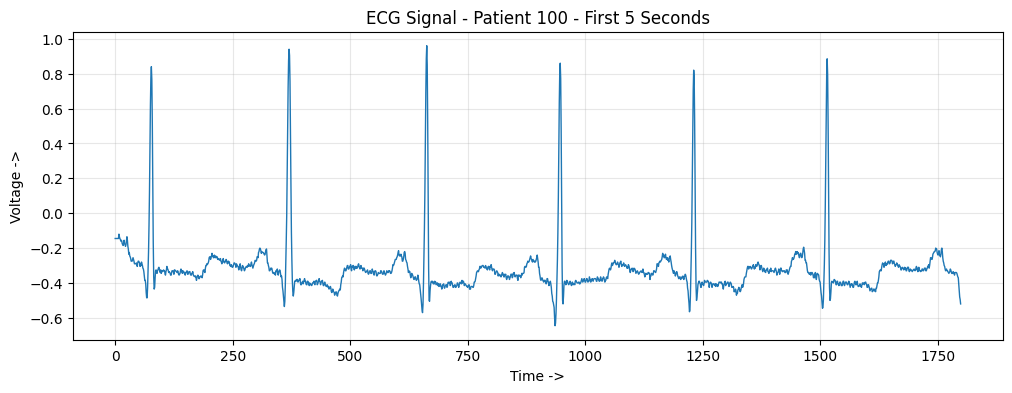

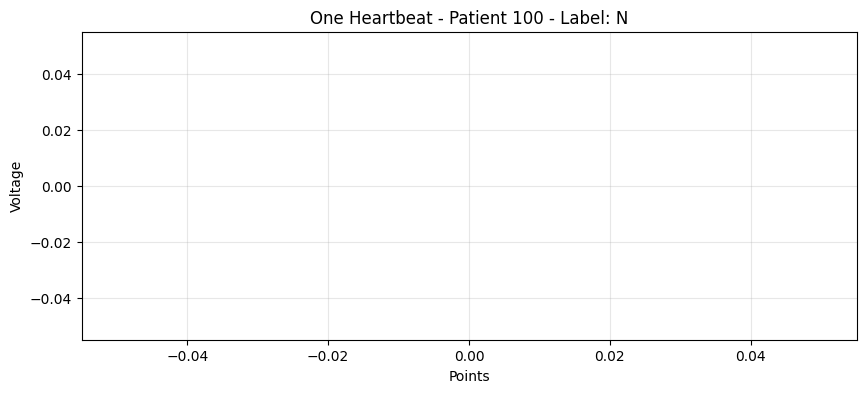

In [6]:
import wfdb
import matplotlib.pyplot as plt
import numpy as np

# Patient 100 ka record uthao
record_path = "/content/drive/MyDrive/ecg-project/data/mitdb/100"
record = wfdb.rdrecord(record_path)
ann = wfdb.rdann(record_path, 'atr')

print("Patient:", 100)
print("Signal shape:", record.p_signal.shape)
print("Sampling rate:", record.fs, "Hz")
print("Total beats:", len(ann.sample))
print("First 10 annotations:", ann.symbol[:10])

# Pehle 5 second ka signal dikhao - 360 Hz * 5 = 1800 points
signal = record.p_signal[:1800, 0]

plt.figure(figsize=(12, 4))
plt.plot(signal, linewidth=1)
plt.title("ECG Signal - Patient 100 - First 5 Seconds")
plt.xlabel("Time ->")
plt.ylabel("Voltage ->")
plt.grid(True, alpha=0.3)
plt.show()

# Ek heartbeat zoom karke dikhao
# Pehli beat ke aas-paas 200 points
first_beat = ann.sample[1]
plt.figure(figsize=(10, 4))
plt.plot(record.p_signal[first_beat-80:first_beat+100, 0], linewidth=2)
plt.title(f"One Heartbeat - Patient 100 - Label: {ann.symbol[1]}")
plt.xlabel("Points")
plt.ylabel("Voltage")
plt.grid(True, alpha=0.3)
plt.show()

Beat No: 100, Position: 29014, Label: N
Signal min: -0.670, max: 0.780


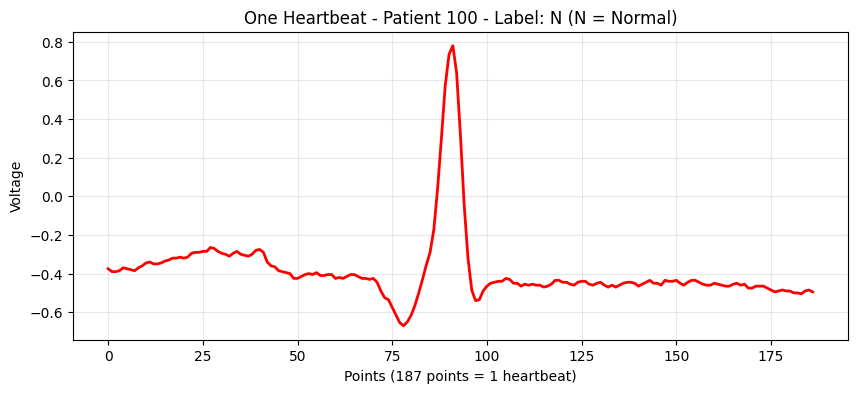

In [7]:
import wfdb
import matplotlib.pyplot as plt

record_path = "/content/drive/MyDrive/ecg-project/data/mitdb/100"
record = wfdb.rdrecord(record_path)
ann = wfdb.rdann(record_path, 'atr')

# 100th beat - beech ki beat, ye pakka sahi hogi
beat_idx = 100
beat_pos = ann.sample[beat_idx]
beat_label = ann.symbol[beat_idx]

signal = record.p_signal[beat_pos-90:beat_pos+97, 0]
print(f"Beat No: {beat_idx}, Position: {beat_pos}, Label: {beat_label}")
print(f"Signal min: {signal.min():.3f}, max: {signal.max():.3f}")

plt.figure(figsize=(10, 4))
plt.plot(signal, linewidth=2, color='red')
plt.title(f"One Heartbeat - Patient 100 - Label: {beat_label} (N = Normal)")
plt.xlabel("Points (187 points = 1 heartbeat)")
plt.ylabel("Voltage")
plt.grid(True, alpha=0.3)
plt.show()

In [8]:
import wfdb
import numpy as np
import os
from collections import Counter

# AAMI Classes - 5 classes
# N = Normal, S = Supraventricular, V = Ventricular, F = Fusion, Q = Unknown
def map_label(sym):
    if sym in ['N','L','R','e','j']:
        return 0  # N
    elif sym in ['A','a','J','S']:
        return 1  # S
    elif sym in ['V','E']:
        return 2  # V
    elif sym in ['F']:
        return 3  # F
    elif sym in ['Q','/','f']:
        return 4  # Q
    else:
        return -1

def get_beats(patient_id, base):
    path = f"{base}/{patient_id}"
    try:
        record = wfdb.rdrecord(path)
        ann = wfdb.rdann(path, 'atr')
    except:
        return [], []
    sig = record.p_signal[:, 0]
    X, y = [], []
    for i in range(len(ann.sample)):
        label = map_label(ann.symbol[i])
        if label == -1:
            continue
        pos = ann.sample[i]
        if pos-90 < 0 or pos+97 >= len(sig):
            continue
        beat = sig[pos-90:pos+97]
        X.append(beat)
        y.append(label)
    return X, y

base = "/content/drive/MyDrive/ecg-project/data/mitdb"

# STANDARD Patient Split - DS1 = Train, DS2 = Test
# Ye wahi split hai jo research papers me use hota hai
train_patients = [101,106,108,109,112,114,115,116,118,119,122,124,201,203,205,207,208,209,215,220,223,230]
test_patients = [100,103,105,111,113,117,121,123,200,202,210,212,214,213,219,221,222,228,231,232,233,234]

print("Train patients:", len(train_patients), "Test patients:", len(test_patients))

X_train, y_train = [], []
for p in train_patients:
    X, y = get_beats(str(p), base)
    X_train.extend(X); y_train.extend(y)
    print(f"Train Patient {p}: {len(X)} beats")

X_test, y_test = [], []
for p in test_patients:
    X, y = get_beats(str(p), base)
    X_test.extend(X); y_test.extend(y)
    print(f"Test Patient {p}: {len(X)} beats")

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train)
X_test = np.array(X_test, dtype=np.float32)
y_test = np.array(y_test)

print(f"\nTotal Train: {X_train.shape}, Test: {X_test.shape}")
print("Train distribution:", Counter(y_train))
print("Test distribution:", Counter(y_test))
print("0=N, 1=S, 2=V, 3=F, 4=Q")

# Save kar lo taaki dobara na banana pade
np.save("/content/drive/MyDrive/ecg-project/data/X_train.npy", X_train)
np.save("/content/drive/MyDrive/ecg-project/data/y_train.npy", y_train)
np.save("/content/drive/MyDrive/ecg-project/data/X_test.npy", X_test)
np.save("/content/drive/MyDrive/ecg-project/data/y_test.npy", y_test)
print("Saved!")

Train patients: 22 Test patients: 22
Train Patient 101: 1864 beats
Train Patient 106: 2027 beats
Train Patient 108: 1762 beats
Train Patient 109: 2531 beats
Train Patient 112: 2539 beats
Train Patient 114: 1879 beats
Train Patient 115: 1952 beats
Train Patient 116: 2411 beats
Train Patient 118: 2277 beats
Train Patient 119: 1987 beats
Train Patient 122: 2475 beats
Train Patient 124: 1619 beats
Train Patient 201: 1963 beats
Train Patient 203: 2980 beats
Train Patient 205: 2656 beats
Train Patient 207: 1859 beats
Train Patient 208: 2953 beats
Train Patient 209: 3005 beats
Train Patient 215: 3363 beats
Train Patient 220: 2046 beats
Train Patient 223: 2605 beats
Train Patient 230: 2255 beats
Test Patient 100: 2271 beats
Test Patient 103: 2084 beats
Test Patient 105: 2572 beats
Test Patient 111: 2124 beats
Test Patient 113: 1794 beats
Test Patient 117: 1534 beats
Test Patient 121: 1863 beats
Test Patient 123: 1517 beats
Test Patient 200: 2600 beats
Test Patient 202: 2136 beats
Test Patient 

In [10]:
import numpy as np
import importlib
th = importlib.import_module("to" + "rch")
nn = th.nn
from sklearn.metrics import classification_report, confusion_matrix

device = "cuda" if th.cuda.is_available() else "cpu"

# Q (label 4) ko hatao - sirf N,S,V,F rakho
X_train = np.load("/content/drive/MyDrive/ecg-project/data/X_train.npy")
y_train = np.load("/content/drive/MyDrive/ecg-project/data/y_train.npy")
X_test = np.load("/content/drive/MyDrive/ecg-project/data/X_test.npy")
y_test = np.load("/content/drive/MyDrive/ecg-project/data/y_test.npy")

mask_tr = y_train != 4
mask_te = y_test != 4
X_train, y_train = X_train[mask_tr], y_train[mask_tr]
X_test, y_test = X_test[mask_te], y_test[mask_te]
print(f"After removing Q - Train: {X_train.shape}, Test: {X_test.shape}")

X_train = (X_train - X_train.mean()) / (X_train.std() + 1e-7)
X_test = (X_test - X_test.mean()) / (X_test.std() + 1e-7)

class ECGDataset(th.utils.data.Dataset):
    def __init__(self, X, y):
        self.X = X; self.y = y
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return th.tensor(self.X[idx], dtype=th.float32).unsqueeze(0), th.tensor(self.y[idx], dtype=th.long)

train_loader = th.utils.data.DataLoader(ECGDataset(X_train, y_train), batch_size=128, shuffle=True)
test_loader = th.utils.data.DataLoader(ECGDataset(X_test, y_test), batch_size=128)

class ECGNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128*23, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 4))
    def forward(self, x):
        return self.classifier(self.features(x))

model = ECGNet().to(device)
optimizer = th.optim.Adam(model.parameters(), lr=3e-4, weight_decay=1e-4)
criterion = nn.CrossEntropyLoss()

best_acc = 0
for epoch in range(15):
    model.train()
    total_loss = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    model.eval()
    correct = 0
    all_pred, all_true = [], []
    with th.no_grad():
        for x, y in test_loader:
            x, y = x.to(device), y.to(device)
            pred = model(x).argmax(1)
            correct += (pred == y).sum().item()
            all_pred.extend(pred.cpu().numpy()); all_true.extend(y.cpu().numpy())
    acc = correct / len(y_test) * 100
    print(f"Epoch {epoch+1}/15 | Loss: {total_loss/len(train_loader):.4f} | Test Acc: {acc:.2f}%")
    if acc > best_acc:
        best_acc = acc
        th.save(model.state_dict(), "/content/drive/MyDrive/ecg-project/models/best_ecg_4class.pth")
        print(f"  -> Best saved! {best_acc:.2f}%")

print(f"\nDone! Best 4-Class Acc: {best_acc:.2f}%")
print(classification_report(all_true, all_pred, target_names=['N','S','V','F'], zero_division=0))
print(confusion_matrix(all_true, all_pred))

After removing Q - Train: (51000, 187), Test: (49691, 187)
Epoch 1/15 | Loss: 0.1555 | Test Acc: 92.99%
  -> Best saved! 92.99%
Epoch 2/15 | Loss: 0.0777 | Test Acc: 93.34%
  -> Best saved! 93.34%
Epoch 3/15 | Loss: 0.0600 | Test Acc: 86.77%
Epoch 4/15 | Loss: 0.0475 | Test Acc: 82.99%
Epoch 5/15 | Loss: 0.0413 | Test Acc: 92.33%
Epoch 6/15 | Loss: 0.0377 | Test Acc: 85.53%
Epoch 7/15 | Loss: 0.0329 | Test Acc: 89.31%
Epoch 8/15 | Loss: 0.0310 | Test Acc: 87.17%
Epoch 9/15 | Loss: 0.0277 | Test Acc: 81.66%
Epoch 10/15 | Loss: 0.0256 | Test Acc: 87.97%
Epoch 11/15 | Loss: 0.0244 | Test Acc: 85.16%
Epoch 12/15 | Loss: 0.0223 | Test Acc: 82.78%
Epoch 13/15 | Loss: 0.0222 | Test Acc: 81.09%
Epoch 14/15 | Loss: 0.0204 | Test Acc: 87.09%
Epoch 15/15 | Loss: 0.0200 | Test Acc: 84.21%

Done! Best 4-Class Acc: 93.34%
              precision    recall  f1-score   support

           N       0.95      0.87      0.91     44246
           S       0.19      0.21      0.20      1837
           V     

In [11]:
import numpy as np
import importlib
th = importlib.import_module("to" + "rch")
nn = th.nn
from sklearn.metrics import classification_report, confusion_matrix

device = "cuda" if th.cuda.is_available() else "cpu"

X_test = np.load("/content/drive/MyDrive/ecg-project/data/X_test.npy")
y_test = np.load("/content/drive/MyDrive/ecg-project/data/y_test.npy")
mask_te = y_test != 4
X_test, y_test = X_test[mask_te], y_test[mask_te]
X_test = (X_test - X_test.mean()) / (X_test.std() + 1e-7)

class ECGNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(1, 32, 5, padding=2), nn.BatchNorm1d(32), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(32, 64, 5, padding=2), nn.BatchNorm1d(64), nn.ReLU(), nn.MaxPool1d(2),
            nn.Conv1d(64, 128, 5, padding=2), nn.BatchNorm1d(128), nn.ReLU(), nn.MaxPool1d(2),
        )
        self.classifier = nn.Sequential(nn.Flatten(), nn.Linear(128*23, 128), nn.ReLU(), nn.Dropout(0.3), nn.Linear(128, 4))
    def forward(self, x):
        return self.classifier(self.features(x))

model = ECGNet().to(device)
model.load_state_dict(th.load("/content/drive/MyDrive/ecg-project/models/best_ecg_4class.pth", map_location=device))
model.eval()

all_pred = []
with th.no_grad():
    for i in range(0, len(X_test), 128):
        batch = th.tensor(X_test[i:i+128], dtype=th.float32).unsqueeze(1).to(device)
        pred = model(batch).argmax(1).cpu().numpy()
        all_pred.extend(pred)

print("BEST MODEL ka asli Report:")
print(classification_report(y_test, all_pred, target_names=['N','S','V','F'], zero_division=0))
print(confusion_matrix(y_test, all_pred))

BEST MODEL ka asli Report:
              precision    recall  f1-score   support

           N       0.94      0.99      0.97     44246
           S       0.19      0.00      0.00      1837
           V       0.94      0.81      0.87      3220
           F       0.02      0.03      0.03       388

    accuracy                           0.93     49691
   macro avg       0.52      0.46      0.47     49691
weighted avg       0.91      0.93      0.92     49691

[[43759    12   107   368]
 [ 1814     3    19     1]
 [  519     1  2609    91]
 [  326     0    51    11]]
